# 🏭 Factory Maintenance Analysis with SQL
**Author:** Ayush Ramtekkar · **Tools:** Python, pandas, SQLite (SQL), matplotlib

**Business question:** *Where is the factory's maintenance money going, and what should we fix first?*

Two tables are combined with SQL:
- `machines` – 10 machines with type, power (kW), daily hours and operating temperature (°C)
- `maintenance` – 8 repair records with month, cost (EUR) and issue

## Setup: load the data into an SQL database

In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

machines = pd.read_csv("factory.csv")
maintenance = pd.read_csv("maintenance.csv")

conn = sqlite3.connect(":memory:")
machines.to_sql("machines", conn, index=False)
maintenance.to_sql("maintenance", conn, index=False)

def sql(query):
    return pd.read_sql(query, conn)

## Q1: How much did we spend on repairs in total?

In [2]:
sql("""
SELECT SUM(repair_cost_eur) AS total_spend
FROM maintenance
""")

,total_spend
0,3490


💡 **Insight:** **3,490 EUR** was spent on 8 repairs.

## Q2: Which machine type costs the most to repair?

In [3]:
sql("""
SELECT machines.type, SUM(maintenance.repair_cost_eur) AS total_cost
FROM maintenance
JOIN machines ON maintenance.machine = machines.machine
GROUP BY machines.type
ORDER BY total_cost DESC
""")

,type,total_cost
0,compressor,1610
1,chiller,900
2,oven,680
3,pump,210
4,fan,90


💡 **Insight:** **Compressors** cost the most: 1,610 EUR, or **46%** of all repair spend.

## Q2b: Most expensive single repair per type

In [4]:
sql("""
SELECT machines.type, MAX(maintenance.repair_cost_eur) AS most_expensive
FROM maintenance
JOIN machines ON maintenance.machine = machines.machine
GROUP BY machines.type
ORDER BY most_expensive DESC
""")

,type,most_expensive
0,chiller,900
1,compressor,620
2,oven,380
3,pump,210
4,fan,90


💡 **Insight:** The **chiller** had the single most expensive repair (900 EUR), but compressors cost more in total because they break more often.

## Q3: What is the most common issue?

In [5]:
sql("""
SELECT maintenance.issue, COUNT(*) AS num_repairs
FROM maintenance
GROUP BY maintenance.issue
ORDER BY num_repairs DESC
""")

,issue,num_repairs
0,overheating,3
1,valve,1
2,sensor,1
3,seal,1
4,refrigerant,1
5,belt,1


💡 **Insight:** **Overheating** causes 3 of 8 repairs (38%), which is the #1 problem.

## Q4: How much do hot machines (> 90 °C) cost us?

In [6]:
sql("""
SELECT SUM(maintenance.repair_cost_eur) AS hot_cost
FROM maintenance
JOIN machines ON maintenance.machine = machines.machine
WHERE machines.temp_c > 90
""")

,hot_cost
0,2650


💡 **Insight:** Only 3 machines run above 90 °C, but they cause **2,650 EUR = 76%** of all repair costs.

## Q4b: Hot machine repair costs per type

In [7]:
sql("""
SELECT machines.type, SUM(maintenance.repair_cost_eur) AS hot_cost
FROM maintenance
JOIN machines ON maintenance.machine = machines.machine
WHERE machines.temp_c > 90
GROUP BY machines.type
ORDER BY hot_cost DESC
""")

,type,hot_cost
0,compressor,1070
1,chiller,900
2,oven,680


💡 **Insight:** The hot-machine cost splits across compressor (1,070), chiller (900) and oven (680).

## Q5: Which machines had more than 1 repair?

In [8]:
sql("""
SELECT maintenance.machine, COUNT(*) AS num_repairs
FROM maintenance
GROUP BY maintenance.machine
HAVING COUNT(*) > 1
""")

,machine,num_repairs
0,Compressor A,2
1,Oven J,2


💡 **Insight:** **Compressor A** (95 °C) and **Oven J** (97 °C) broke twice. Both are hot machines.

## Q6: Which machines never needed a repair?

In [9]:
sql("""
SELECT machines.machine, machines.type
FROM machines
LEFT JOIN maintenance ON machines.machine = maintenance.machine
WHERE maintenance.repair_cost_eur IS NULL
""")

,machine,type
0,Pump B,pump
1,Fan C,fan
2,Drill D,drill
3,Oven E,oven


💡 **Insight:** 4 machines never needed a repair, and all of them run at **88 °C or below**.

## Q7: Repairs per machine, including 0

In [10]:
sql("""
SELECT machines.machine, COUNT(maintenance.issue) AS num_repairs
FROM machines
LEFT JOIN maintenance ON machines.machine = maintenance.machine
GROUP BY machines.machine
ORDER BY num_repairs DESC
""")

,machine,num_repairs
0,Oven J,2
1,Compressor A,2
2,Pump G,1
3,Fan H,1
4,Compressor I,1
5,Chiller F,1
6,Pump B,0
7,Oven E,0
8,Fan C,0
9,Drill D,0


💡 **Insight:** A LEFT JOIN keeps all 10 machines, so machines with 0 repairs are visible too.

## Charts

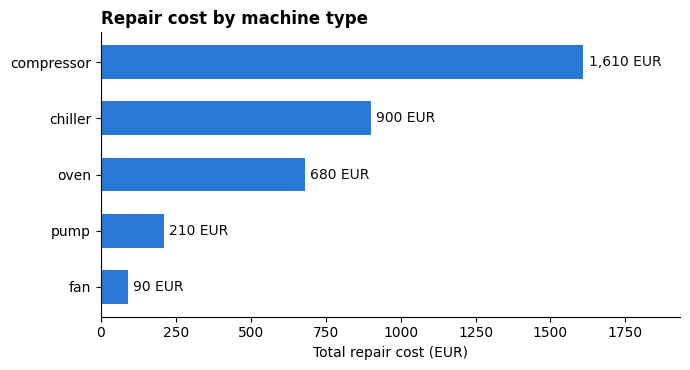

In [11]:
BLUE = "#2a78d6"
by_type = sql("""
SELECT machines.type, SUM(maintenance.repair_cost_eur) AS total_cost
FROM maintenance
JOIN machines ON maintenance.machine = machines.machine
GROUP BY machines.type
ORDER BY total_cost
""")
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.barh(by_type["type"], by_type["total_cost"], color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:,.0f} EUR" for v in by_type["total_cost"]], padding=4, color="#0b0b0b")
ax.set_title("Repair cost by machine type", loc="left", fontweight="bold")
ax.set_xlabel("Total repair cost (EUR)")
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(0, by_type["total_cost"].max() * 1.2)
plt.tight_layout()
plt.savefig("repair_cost_by_type.png", dpi=150)
plt.show()

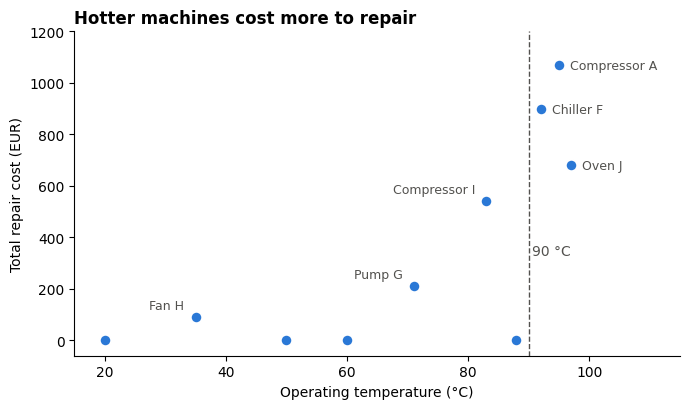

In [12]:
per_machine = sql("""
SELECT machines.machine, machines.temp_c,
       COALESCE(SUM(maintenance.repair_cost_eur), 0) AS total_cost
FROM machines
LEFT JOIN maintenance ON machines.machine = maintenance.machine
GROUP BY machines.machine
""")
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(per_machine["temp_c"], per_machine["total_cost"], s=70, color=BLUE,
           edgecolor="white", linewidth=1.5, zorder=3)
ax.axvline(90, color="#52514e", linestyle="--", linewidth=1)
ax.text(90.5, 330, "90 °C", ha="left", color="#52514e")
for _, r in per_machine[per_machine["total_cost"] > 0].iterrows():
    right = r["temp_c"] > 90
    ax.annotate(r["machine"], (r["temp_c"], r["total_cost"]), textcoords="offset points",
                xytext=(8, -3) if right else (-8, 6), ha="left" if right else "right",
                fontsize=9, color="#52514e")
ax.set_title("Hotter machines cost more to repair", loc="left", fontweight="bold")
ax.set_xlabel("Operating temperature (°C)")
ax.set_ylabel("Total repair cost (EUR)")
ax.set_ylim(-60, 1200)
ax.set_xlim(15, 115)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("temperature_vs_repair_cost.png", dpi=150)
plt.show()

## ✅ Conclusions & recommendations
1. **Heat is the main cost driver.** The 3 machines above 90 °C cause 76% of repair costs, and overheating is the most common issue.
2. **Compressors are the most expensive type** (46% of spend), so check compressor cooling first.
3. **Repeat failures:** Compressor A and Oven J broke twice. Add them to a preventive maintenance plan.
4. **Next step:** track temperature over time to predict failures before they happen (predictive maintenance).